# Charge and exciton transport on a model lattice

This tutorial goes through the transport calculators of VOTCA-XTP on a small model system:

1. a **time-of-flight** (ToF) experiment, solved exactly with the graph random walk (`grw`) and simulated with kinetic Monte Carlo (`kmctof`),
2. **bulk transport** in a periodic box with `kmcmultiple`: mobility, diffusion, and the effect of the carrier density,
3. why ToF and bulk mobilities differ in thin samples,
4. **exciton diffusion** with finite lifetimes and quenchers with `kmclifetime`,
5. the dependence of the mobility on energetic disorder.

Instead of a morphology from molecular dynamics we use a cubic lattice with Gaussian site energies, written by the `latticegen` tool as an ordinary state file. All calculators work the same way on real morphologies (see the thiophene tutorial); on the lattice everything runs in seconds and the parameters are under control. Background: the chapters *Charge and Energy Transport Model* and *Transport Simulations* of the XTP manual.

## Requirements
* VOTCA installed and the environment activated with `VOTCARC.bash` (see the [installation instructions](https://github.com/votca/votca/blob/master/share/sphinx/INSTALL.rst)).
* Python with `numpy` and `matplotlib`.

In Jupyter, `!` runs a shell command.

In [1]:
import glob
import os
import subprocess
import numpy as np
import matplotlib.pyplot as plt

# latticegen does not overwrite state files: remove those of a previous run
for name in ["lattice.hdf5", "small.hdf5"] + glob.glob("slab_*.hdf5") + glob.glob("disorder_*.hdf5"):
    if os.path.exists(name):
        os.remove(name)


def run(command):
    # run a VOTCA command quietly (raises if it fails)
    subprocess.run(command, shell=True, check=True, capture_output=True)


def results(filename):
    # read a 'key value unit' result file into a dictionary
    values = {}
    with open(filename) as f:
        for line in f:
            if line.startswith("#") or not line.strip():
                continue
            key, value = line.split()[:2]
            try:
                values[key] = float(value)
            except ValueError:
                values[key] = value
    return values

## The model system

`latticegen` places sites on a simple cubic lattice with spacing $a$ = 1 nm (`spacing`), connects all pairs closer than `cutoff` (1.5 nm: 6 nearest and 12 next-nearest neighbours), gives them couplings $|J|^2 = J_2\, e^{-(r-a)/\ell}$ and one reorganization energy $\lambda$, and draws Gaussian site energies with standard deviation $\sigma$ (`energy.sigma`). The defaults follow Chen, van der Hoorn, Baumeier, arXiv:2405.15836. We use $10\times10\times10$ sites, $\sigma$ = 0.1 eV (about $4\,k_BT$ at room temperature), and write parameters for electrons, holes and singlets.

In [2]:
!xtp_tools -e latticegen -c job_name=lattice dims="10 10 10" states="e h s" energy.sigma=0.1 energyfile=lattice_E.txt

========   VOTCA (http://www.votca.org)   ========

please read and cite: https://doi.org/10.21105/joss.06864
and submit bugs to https://github.com/votca/votca/issues

xtp_tools, version 2026-dev gitid: e285215 (compiled Nov  1 2026, 21:29:02)

Initializing tool
... latticegen Evaluating tool
... latticegen  Using 1 threads


... ... Lattice 10x10x10: 1000 sites, 9000 pairs
... ... Site energies: mean -0.767305 eV, standard deviation 0.099181 eVCreating statefile lattice.hdf5
Frame with id 0 was not in statefile lattice.hdf5 ,adding it now.


Wrote MD topology (step = 0, time = 0) to lattice.hdf5
... . 

... ... Wrote lattice.hdf5
... ... Wrote site energies to lattice_E.txt


Please cite the methods used in this run:
  [1] Baumeier, Wehner, Renaud, Zapata Ruiz, Halver, Madhikar, Gerritsen,
      Tirimbo, Sijen, Rosenberger, Brown, Sundaram, Krajniak, Bernhardt, and
      Junghans, VOTCA: multiscale frameworks for quantum and classical
      simulations in soft matter, J. Open Source Softw. 9, 6864 (2024),
      doi:10.21105/joss.06864
  [2] Chen, van der Hoorn, and Baumeier, A graph random walk method for
      calculating time-of-flight charge mobility in organic semiconductors
      from multiscale simulations, Multiscale Model. Simul. 23, 1439 (2025),
      doi:10.1137/24M1658085


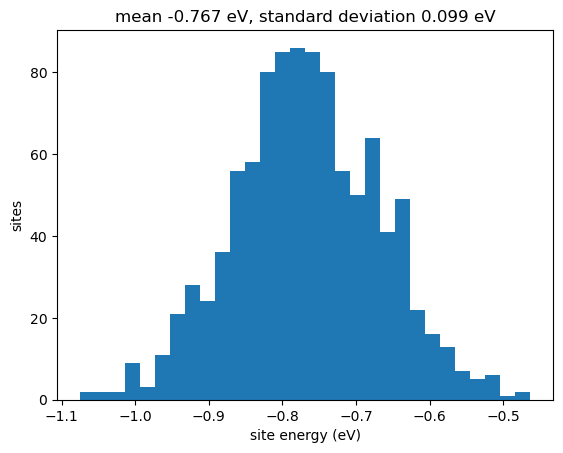

In [3]:
E = np.loadtxt("lattice_E.txt")[:, 4]
plt.hist(E, bins=30)
plt.xlabel("site energy (eV)")
plt.ylabel("sites")
plt.title(f"mean {E.mean():.3f} eV, standard deviation {E.std():.3f} eV")
plt.show()

## Time of flight: exact hitting times with `grw`

For the ToF geometry the periodicity is cut across one box vector (`tof.axis`, default `a`): the sample becomes a slab, periodic in the two other directions. Holes are injected in a 1 nm thick source slab at one face and absorbed in a 1 nm thick sink slab at the other; a field of $2\cdot10^7$ V/m (200 kV/cm) drives them across.

`grw` computes the mean time until a carrier, injected uniformly on the source sites, reaches the sink, from a sparse linear system: no random numbers are involved. The mobility follows as $\mu = L/(\langle t\rangle F)$ with the transport length $L$ printed in the log.

In [4]:
!xtp_run -e grw -c carriertype=hole field="2e7 0 0" -f lattice.hdf5

========   VOTCA (http://www.votca.org)   ========

please read and cite: https://doi.org/10.21105/joss.06864
and submit bugs to https://github.com/votca/votca/issues

xtp_run, version 2026-dev gitid: e285215 (compiled Nov  1 2026, 21:29:02)

Initializing calculator
... grw
1 frames in statefile, Ids are: 0 
Starting at frame 0
Evaluating frame 0
Import MD Topology (i.e. frame 0) from lattice.hdf5


.... 
... grw
 Using 1 threads
 ... 
-----------------------------------
  GRAPH RANDOM WALK TIME OF FLIGHT
-----------------------------------
 ... ToF graph for holes
  periodicity cut across box vector a, normal (1 0 0), thickness 10 nm
  sites: 1000 (0 of ignored types), hops: 17000, pairs cut at the periodic boundary: 500
  sources: 100 connected, 0 without path to a sink (excluded)
  sinks: 100, sites without path to a sink: 0
  transport length (mean source to first sink): 9 nm
  detailed balance: yes (max deviation of ln(w_ij/w_ji) 8.88178e-15)
 ... Solver: cholesky (LDLT of the symmetrized generator), 900 unknowns, 0 iterations, backward error 2.1465e-15 after 0 refinement steps
 ... Time of flight (uniform injection over 100 source sites): mean 1.944e-10 s
 ... Standard deviation of the hitting time: 2.54188e-10 s
 ... Harmonic mean over the injection states: 1.89596e-10 s
 ... Mobility L/(tau F): 0.0231482 cm^2/Vs (mean), 0.0237347 cm^2/Vs (harmonic), with L = 9 nm and F = 2

Besides the log, every transport calculator writes a short result file with `key value unit` lines (here `grw_results.dat`), which is convenient for scripts. `grw_occupation.dat` contains the expected time $g_A$ each site $A$ is occupied before the hole arrives at the sink (averaged over a uniform injection on the source sites), and the *fraction of the time of flight* $g_A/\langle T\rangle$, which adds up to 1 over all sites. Plotted against the site energy, it shows where the time of flight is spent: a few low-energy sites (traps) hold the carrier for a large part of it. (All output quantities are defined in the section *Output quantities* of the manual chapter *Transport Simulations*.)

time of flight 1.944e-10 s, mobility 2.315e-02 cm^2/Vs


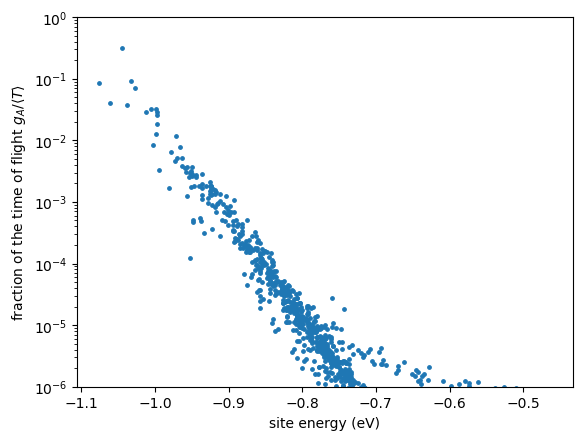

the 10 most occupied sites hold 77% of the time of flight


In [5]:
grw = results("grw_results.dat")
print(f"time of flight {grw['tau_mean']:.3e} s, mobility {grw['mobility_mean']:.3e} cm^2/Vs")

occ = np.loadtxt("grw_occupation.dat", usecols=(1, 2, 4, 5))
x, energy, time, fraction = occ.T
plt.scatter(energy, fraction, s=6)
plt.yscale("log")
plt.ylim(1e-6, 1)
plt.xlabel("site energy (eV)")
plt.ylabel(r"fraction of the time of flight $g_A/\langle T\rangle$")
plt.show()
order = np.argsort(fraction)[::-1]
print(f"the 10 most occupied sites hold {fraction[order[:10]].sum():.0%} of the time of flight")

Because `grw` needs no sampling, scans are cheap. Here the field dependence of the ToF mobility:

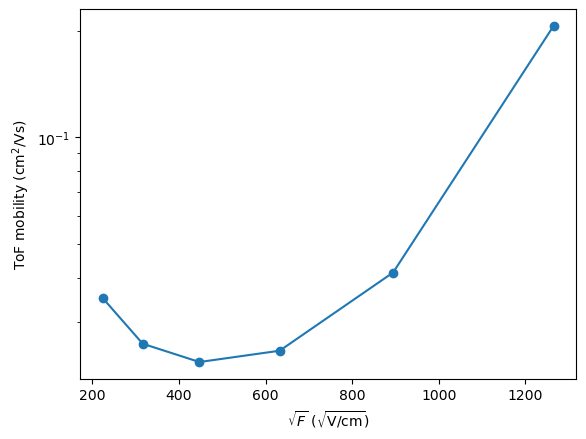

In [6]:
fields = np.array([0.5, 1, 2, 4, 8, 16]) * 1e7  # V/m
mu = []
for F in fields:
    run(f'xtp_run -e grw -c carriertype=hole field="{F} 0 0" resultfile=scan.dat sourcefile=x occupationfile=x -f lattice.hdf5')
    mu.append(results("scan.dat")["mobility_mean"])
plt.semilogy(np.sqrt(fields / 1e2), mu, "o-")  # sqrt(V/cm)
plt.xlabel(r"$\sqrt{F}$ ($\sqrt{\mathrm{V/cm}}$)")
plt.ylabel("ToF mobility (cm$^2$/Vs)")
plt.show()

At high fields the mobility rises with $\sqrt{F}$, as often observed (Poole-Frenkel-like behaviour), because the field lowers the barriers out of traps. At low fields it rises again: across a 9 nm slab diffusion alone brings carriers to the sink, so $\langle t\rangle$ no longer scales as $1/F$ and $L/(\langle t\rangle F)$ is not a drift mobility any more. A ToF mobility is only meaningful when drift dominates, i.e. for $qFL \gg k_BT$ (here $F\gg 3\cdot10^6$ V/m).

## The same with kinetic Monte Carlo: `kmctof`

`kmctof` simulates the experiment: in each of `runs` runs a hole is injected on a random source site and hops until it reaches the sink. The mean transit time agrees with `grw` within the statistical error. In addition, KMC gives the distribution of transit times (`kmctof_runs.dat`, one line per run) and the transient current (`kmctof_current.dat`), and it can handle many carriers, pulses and time-dependent rates.

The transient current is computed as in an experiment, after Ramo and Shockley: every hop moves charge by $\Delta x$ along the transport direction and induces a current $q\,\Delta x/L$ in the electrodes. `kmctof` sums these over all runs on a logarithmic time axis and divides by the number of injected carriers $N_\mathrm{inj}$ and the bin width:

$$I(t)=\frac{1}{L\,N_\mathrm{inj}\,\Delta t}\sum_{\text{hops in }[t,t+\Delta t)}\Delta x \qquad (\text{1/s}).$$

So $I(t)$ is the current per injected carrier in units of the elementary charge; for $N_\mathrm{inj}$ carriers of charge $q$ the measured current is $q\,N_\mathrm{inj}\,I(t)$. Its time integral is the mean displacement per injected carrier in units of $L$. The file also contains the *collected fraction*, the number of carriers absorbed up to the end of each bin divided by $N_\mathrm{inj}$.

In [7]:
!xtp_run -e kmctof -c carriertype=hole field="2e7 0 0" runs=4000 -f lattice.hdf5

========   VOTCA (http://www.votca.org)   ========

please read and cite: https://doi.org/10.21105/joss.06864
and submit bugs to https://github.com/votca/votca/issues

xtp_run, version 2026-dev gitid: e285215 (compiled Nov  1 2026, 21:29:02)

Initializing calculator
... kmctof
1 frames in statefile, Ids are: 0 
Starting at frame 0
Evaluating frame 0
Import MD Topology (i.e. frame 0) from lattice.hdf5


.... 
... kmctof
 Using 1 threads
 ... 
-----------------------------------
  KINETIC MONTE CARLO TIME OF FLIGHT
-----------------------------------
 ... ToF graph for holes
  periodicity cut across box vector a, normal (1 0 0), thickness 10 nm
  sites: 1000 (0 of ignored types), hops: 17000, pairs cut at the periodic boundary: 500
  sources: 100 connected, 0 without path to a sink (excluded)
  sinks: 100, sites without path to a sink: 0
  transport length (mean source to first sink): 9 nm
  detailed balance: yes (max deviation of ln(w_ij/w_ji) 8.88178e-15)
 ... Waiting times: exponential
 ... 4000 runs, 1 pulse(s) of 1 carrier(s), 1 thread(s)


 ... 341826 hops, 0 null events (occupied site or rejected), 0.087288 s
 ... First arrival: 1.87874e-10 +- 3.89775e-12 s (standard error, 4000 runs), standard deviation 2.46515e-10 s, largest 1 % of the runs: 8.47518 % of the sum
 ... Mean transit time per carrier: 1.87874e-10 +- 3.89775e-12 s (standard error, 4000 runs), standard deviation 2.46515e-10 s, largest 1 % of the runs: 8.47518 % of the sum
 ... Mobility L/(tau F) from the mean transit time: 0.0239522 cm^2/VsChanges have not been written to state file.

Please cite the methods used in this run:
  [1] Baumeier, Wehner, Renaud, Zapata Ruiz, Halver, Madhikar, Gerritsen,
      Tirimbo, Sijen, Rosenberger, Brown, Sundaram, Krajniak, Bernhardt, and
      Junghans, VOTCA: multiscale frameworks for quantum and classical
      simulations in soft matter, J. Open Source Softw. 9, 6864 (2024),
      doi:10.21105/joss.06864
  [2] Ruehle, Lukyanov, May, Schrader, Vehoff, Kirkpatrick, Baumeier, and
      Andrienko, Microscopic simulations

KMC 1.879e-10 +- 3.9e-12 s, grw 1.944e-10 s: -1.7 standard errors
the slowest 1 % of the runs contribute 8% of the sum of the transit times


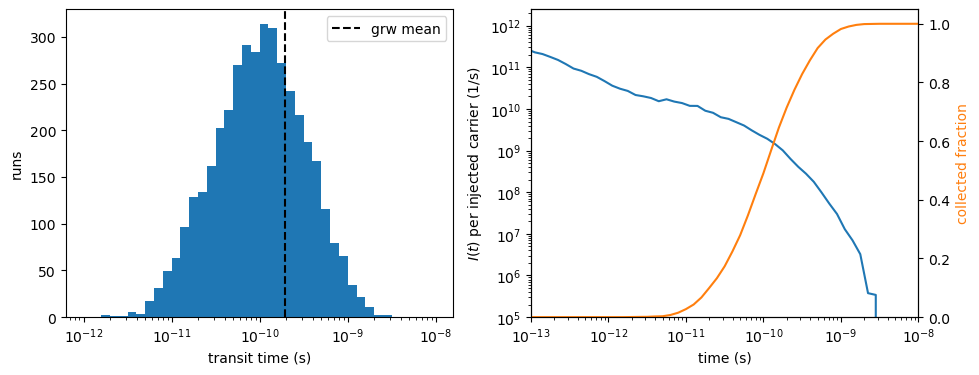

integral of I(t): 1.000 (mean displacement / L), collected fraction: 1.000


In [8]:
tof = results("kmctof_results.dat")
z = (tof["transit_mean"] - grw["tau_mean"]) / tof["transit_error"]
print(f"KMC {tof['transit_mean']:.3e} +- {tof['transit_error']:.1e} s, grw {grw['tau_mean']:.3e} s: {z:+.1f} standard errors")
print(f"the slowest 1 % of the runs contribute {tof['transit_top_percent_share']:.0%} of the sum of the transit times")

transit = np.loadtxt("kmctof_runs.dat", usecols=5)
current = np.loadtxt("kmctof_current.dat")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(transit, bins=np.logspace(-12, -8, 41))
ax1.axvline(grw["tau_mean"], color="k", ls="--", label="grw mean")
ax1.set_xscale("log")
ax1.set_xlabel("transit time (s)")
ax1.set_ylabel("runs")
ax1.legend()
ax2.loglog(current[:, 2], current[:, 3], label="current $I(t)$")
ax2.set_xlim(1e-13, 1e-8)
ax2.set_ylim(1e5)
ax2.set_xlabel("time (s)")
ax2.set_ylabel(r"$I(t)$ per injected carrier (1/s)")
ax3 = ax2.twinx()
ax3.semilogx(current[:, 1], current[:, 4], color="C1", label="collected fraction")
ax3.set_ylim(0, 1.05)
ax3.set_ylabel("collected fraction", color="C1")
plt.show()

# the integral of I(t) (with the parts outside the time axis, in the file
# header) is the mean displacement per injected carrier in units of L
with open("kmctof_current.dat") as f:
    header = [line for line in f if "displacement before" in line][0]
# "# displacement before t_low of the first bin: <a>, after the last bin: <b>"
outside = sum(float(part.split(":")[1]) for part in header.split(","))
integral = np.sum(current[:, 3] * (current[:, 1] - current[:, 0])) + outside
print(f"integral of I(t): {integral:.3f} (mean displacement / L), collected fraction: {current[-1, 4]:.3f}")

The transit times spread over more than two decades, with a tail of slow runs in which the hole was caught in a deep trap. How much this tail weighs in the mean is measured by the share of the slowest 1 % of the runs in the sum of all transit times: about 6 % for exponentially distributed times, and `kmctof` warns above 20 %, when a few runs dominate the mean. The transient current shows the typical ToF shape on a double-logarithmic scale: a slowly decaying part while the carriers drift and relax, then a steep drop when they arrive, while the collected fraction rises to 1. On the lattice the integral of $I(t)$ equals the collected fraction, because all source sites lie in one layer and a carrier is absorbed as soon as it reaches the first sink layer, so every collected carrier has moved exactly $L$. In a morphology the source and sink sites are spread over the slabs and the two numbers differ slightly, since $L$ is measured from the mean source position to the first sink sites.

### Two carriers

`grw` also handles two carriers with site exclusion, on pair states. Their number grows as $n^2/2$ (404550 for our 1000 sites, about half a minute), so we use a smaller $6\times6\times6$ lattice. With `observable=first`, the time until the first of two simultaneously injected holes arrives is computed; `kmctof` with `injection.carriers=2` measures the same.

In [9]:
run('xtp_tools -e latticegen -c job_name=small dims="6 6 6" energy.sigma=0.1')
run('xtp_run -e grw -c carriertype=hole field="2e7 0 0" numberofcarriers=2 observable=first resultfile=grw2.dat sourcefile=x occupationfile=x -f small.hdf5')
run('xtp_run -e kmctof -c carriertype=hole field="2e7 0 0" runs=4000 injection.carriers=2 resultfile=kmctof2.dat runfile=x current.file=x -f small.hdf5')
grw2, tof2 = results("grw2.dat"), results("kmctof2.dat")
print(f"unknowns of the two-carrier system: {grw2['unknowns']:.0f}")
print(f"first arrival: grw {grw2['tau_mean']:.3e} s, KMC {tof2['first_mean']:.3e} +- {tof2['first_error']:.1e} s")

unknowns of the two-carrier system: 16110
first arrival: grw 1.642e-11 s, KMC 1.634e-11 +- 2.7e-13 s


## Bulk transport: `kmcmultiple`

In the periodic box (no cut) a fixed number of carriers moves through the periodic images. `kmcmultiple` follows their unwrapped displacements and reports the drift velocity, the mobility along the field and the diffusion tensor. With `exact` (default) it also solves the master equation for a single carrier; for one carrier the KMC must agree with it.

`runtime` is a simulated time in seconds or, above 100, a number of KMC events. Here: 4 independent runs of $2\cdot10^6$ events, so that errors come from the spread over runs. `outputtime=20` samples run 0 every 20 hops for the time file (mean energy of the carriers, distance travelled).

In [10]:
!xtp_run -e kmcmultiple -c carriertype=hole field="2e7 0 0" numberofcarriers=1 runs=4 runtime=2000000 outputtime=20 timefile=time.dat -f lattice.hdf5

========   VOTCA (http://www.votca.org)   ========

please read and cite: https://doi.org/10.21105/joss.06864
and submit bugs to https://github.com/votca/votca/issues

xtp_run, version 2026-dev gitid: e285215 (compiled Nov  1 2026, 21:29:02)

Initializing calculator
... kmcmultiple
1 frames in statefile, Ids are: 0 
Starting at frame 0
Evaluating frame 0
Import MD Topology (i.e. frame 0) from lattice.hdf5


.... 
... kmcmultiple
 Using 1 threads
 ... 
-----------------------------------
      KMC FOR MULTIPLE CHARGES
-----------------------------------
 ... Bulk hopping graph (periodic in a, b and c, no sinks) for holes
  sites: 1000 (0 of ignored types), hops: 18000
  injection sites: 1000
  detailed balance: no (max deviation of ln(w_ij/w_ji) 7.73635)
 ... Rates written to rates.dat
 ... 1 hole(s), density 0.001 nm^-3, 4 run(s), 1 thread(s)
 ... Each run stops after 2000000 KMC events (hops and attempts into occupied sites)
 ... Waiting times: exponential


 ... 8000000 hops, 0 attempts into occupied sites (0 %), 0.499229 s
 ... Observation window of run 0: 0 s to 4.31006e-06 s, 76 blocks of 5.62341e-08 s
 ... Drift velocity (nm/s): 3.592950e+10 2.264056e+09 4.958845e+08
    +- 2.307981e+08 5.652040e+07 3.641007e+07 (standard error over runs)
 ... Mobility along the field: 1.796475e-02 +- 1.153990e-04 cm^2/Vs (1.796475e+12 nm^2/Vs)
 ... Diffusion tensor (nm^2/s):
 2.541074e+11  3.253492e+09  5.903278e+09
 3.253492e+09  4.855484e+10 -2.689300e+08
 5.903278e+09 -2.689300e+08  4.518460e+10
 ...   +- (standard error over runs)
8.260102e+09 9.910417e+09 4.713812e+09
9.910417e+09 2.945042e+09 1.660013e+09
4.713812e+09 1.660013e+09 1.689252e+09
 ...   eigenvalue 4.498102e+10 nm^2/s, direction  2.965317e-02 -1.018210e-01 -9.943607e-01
 ...   eigenvalue 4.854059e+10 nm^2/s, direction  1.280679e-02 -9.946778e-01  1.022354e-01
 ...   eigenvalue 2.543253e+11 nm^2/s, direction 9.994782e-01 1.576618e-02 2.819135e-02


 ... Exact for one carrier (master equation, sparse LU, 1000 sites, backward error 3.382262e-14):
  drift velocity (nm/s): 3.573738e+10 2.274177e+09 4.531325e+08
  diffusion tensor (nm^2/s):
 2.468030e+11  1.612440e+10  5.629060e+09
 1.612440e+10  5.138358e+10 -6.576121e+08
 5.629060e+09 -6.576121e+08  4.614755e+10
 ...   mobility along the field: 1.786869e-02 cm^2/Vs
 ...   KMC - exact mobility: 8.324248e-01 standard errors
 ... Occupation probabilities written to occupation.dat


 ... Trajectory of run 0 written to trajectory.csv

Changes have not been written to state file.

Please cite the methods used in this run:
  [1] Baumeier, Wehner, Renaud, Zapata Ruiz, Halver, Madhikar, Gerritsen,
      Tirimbo, Sijen, Rosenberger, Brown, Sundaram, Krajniak, Bernhardt, and
      Junghans, VOTCA: multiscale frameworks for quantum and classical
      simulations in soft matter, J. Open Source Softw. 9, 6864 (2024),
      doi:10.21105/joss.06864
  [2] Ruehle, Lukyanov, May, Schrader, Vehoff, Kirkpatrick, Baumeier, and
      Andrienko, Microscopic simulations of charge transport in disordered
      organic semiconductors, J. Chem. Theory Comput. 7, 3335 (2011),
      doi:10.1021/ct200388s


KMC mobility 1.796e-02 +- 1.2e-04 cm^2/Vs, exact 1.787e-02 cm^2/Vs


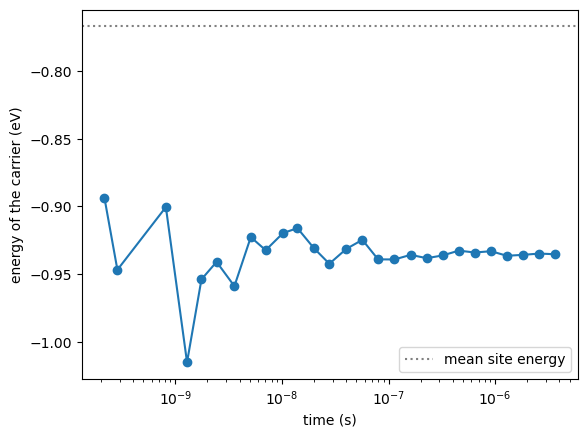

In [11]:
bulk = results("kmcmultiple_results.dat")
print(f"KMC mobility {bulk['mobility']:.3e} +- {bulk['mobility_error']:.1e} cm^2/Vs, exact {bulk['exact_mobility']:.3e} cm^2/Vs")

t, steps, energy = np.loadtxt("time.dat", skiprows=1, usecols=(0, 1, 2)).T
# average the energy over logarithmic time bins
edges = np.logspace(np.log10(t[1]), np.log10(t[-1]), 30)
which = np.digitize(t, edges)
bins = [b for b in range(1, len(edges)) if np.any(which == b)]
plt.semilogx([t[which == b].mean() for b in bins], [energy[which == b].mean() for b in bins], "o-")
plt.axhline(E.mean(), color="gray", ls=":", label="mean site energy")
plt.xlabel("time (s)")
plt.ylabel("energy of the carrier (eV)")
plt.legend()
plt.show()

The carrier starts on a random site (on average at the mean site energy) and relaxes into the low-energy tail of the density of states within a fraction of a nanosecond, i.e. within the first few samples; afterwards its energy fluctuates around the equilibrium value. For an infinite Gaussian density of states this would be $\bar\varepsilon-\sigma^2/k_BT$, 0.39 eV below the mean; in 1000 sites the few deepest sites set it. In long runs this transient hardly matters; otherwise the option `equilibration` leaves it out of the averages.

### Carrier density

With more carriers, the deepest traps fill up and the remaining carriers move faster, while exclusion (a site holds one carrier) starts to block hops. KMC includes both; the exact value is that of an isolated carrier.

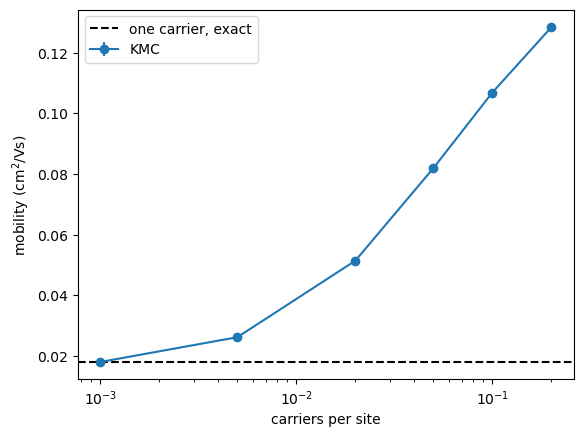

In [12]:
carriers = [1, 5, 20, 50, 100, 200]
mu, err = [], []
for n in carriers:
    run(f'xtp_run -e kmcmultiple -c carriertype=hole field="2e7 0 0" numberofcarriers={n} runs=4 runtime=2000000 outputtime=0 exact=false resultfile=density.dat ratefile=x occfile=x -f lattice.hdf5')
    r = results("density.dat")
    mu.append(r["mobility"])
    err.append(r["mobility_error"])
density = np.array(carriers) / 1000  # carriers per site
plt.errorbar(density, mu, yerr=err, fmt="o-", label="KMC")
plt.axhline(bulk["exact_mobility"], color="k", ls="--", label="one carrier, exact")
plt.xscale("log")
plt.xlabel("carriers per site")
plt.ylabel("mobility (cm$^2$/Vs)")
plt.legend()
plt.show()

## Why ToF and bulk mobilities differ

The ToF mobility from `grw` above is higher than the bulk mobility of the same lattice. In a thin slab the carriers cross the sample before they have relaxed into the deep tail of the density of states (dispersive transport); the bulk value describes carriers in equilibrium. Making the slab thicker along the transport direction shows the approach of the ToF mobility to the bulk value. For every slab we compare with the bulk mobility of the same lattice (the exact single-carrier value from `kmcmultiple`, whose KMC part we keep minimal), for three disorder realizations (`energy.seed`):

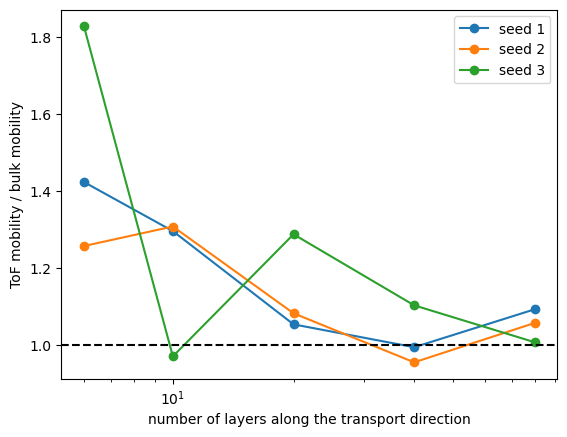

In [13]:
lengths = [6, 10, 20, 40, 80]
for seed in [1, 2, 3]:
    ratio = []
    for n in lengths:
        name = f"slab_{n}_{seed}"
        run(f'xtp_tools -e latticegen -c job_name={name} dims="{n} 10 10" energy.sigma=0.1 energy.seed={seed}')
        run(f'xtp_run -e grw -c carriertype=hole field="2e7 0 0" resultfile=slab_tof.dat sourcefile=x occupationfile=x -f {name}.hdf5')
        run(f'xtp_run -e kmcmultiple -c carriertype=hole field="2e7 0 0" runtime=1000 outputtime=0 resultfile=slab_bulk.dat ratefile=x occfile=x -f {name}.hdf5')
        ratio.append(results("slab_tof.dat")["mobility_mean"] / results("slab_bulk.dat")["exact_mobility"])
    plt.semilogx(lengths, ratio, "o-", label=f"seed {seed}")
plt.axhline(1, color="k", ls="--")
plt.xlabel("number of layers along the transport direction")
plt.ylabel("ToF mobility / bulk mobility")
plt.legend()
plt.show()

Thin slabs give ToF mobilities 25-80 % above the bulk value; from about 20 layers on, the two agree within about 10-30 %, with a large scatter between realizations. The bulk mobility itself varies by up to an order of magnitude between realizations of these small lattices, because it is set by the few deepest sites: real studies need large systems and several realizations.

## Exciton diffusion with finite lifetimes: `kmclifetime`

Excitons hop like charges (here: singlets with the same rate parameters) but decay with a site-dependent rate. `kmclifetime` reads the lifetime of every site from an XML file. We first give all sites a lifetime of 1 ns, then turn 2 % of the sites into quenchers with a lifetime of 1 ps.

In [14]:
def write_lifetimes(filename, lifetimes):
    with open(filename, "w") as f:
        f.write("<lifetimes>\n")
        for i, tau in enumerate(lifetimes):
            f.write(f'  <site id="{i}">{tau:.6e}</site>\n')
        f.write("</lifetimes>\n")


lifetimes = np.full(1000, 1e-9)
write_lifetimes("lifetimes.xml", lifetimes)
rng = np.random.default_rng(3)
quenchers = rng.choice(1000, size=20, replace=False)
lifetimes[quenchers] = 1e-12
write_lifetimes("lifetimes_quenched.xml", lifetimes)

In [15]:
!xtp_run -e kmclifetime -c numberofinsertions=20000 runs=4 -f lattice.hdf5

========   VOTCA (http://www.votca.org)   ========

please read and cite: https://doi.org/10.21105/joss.06864
and submit bugs to https://github.com/votca/votca/issues

xtp_run, version 2026-dev gitid: e285215 (compiled Nov  1 2026, 21:29:02)

Initializing calculator
... kmclifetime
1 frames in statefile, Ids are: 0 
Starting at frame 0
Evaluating frame 0
Import MD Topology (i.e. frame 0) from lattice.hdf5


.... 
... kmclifetime
 Using 1 threads
 ... 
-----------------------------------
      KMC WITH FINITE LIFETIMES
-----------------------------------
 ... Bulk hopping graph (periodic in a, b and c, no sinks) for singlets
  sites: 1000 (0 of ignored types), hops: 18000
  injection sites: 1000
  detailed balance: yes (max deviation of ln(w_ij/w_ji) 7.10543e-15)
 ... Rates written to rates.dat


 ... Exact for one singlet (sparse LU, backward error 5.85203e-11):
 ...   lifetime 1.000000e-09 s, diffusion length sqrt(<R^2>) 1.545079e+01 nm, per direction sqrt(<R_a^2>) 8.904415e+00 9.153696e+00 8.697594e+00 nm
 ... 1 singlet(s) at a time, 20000 decays in 4 run(s), 1 thread(s), waiting times: exponential


 ... 20000 decays, 9099297 hops, 0 attempts into occupied sites, 1.994883e-05 s simulated, 6.030150e-01 s
 ... Average lifetime: 9.974416e-10 +- 7.082321e-12 s (standard error)
  hops per singlet: 4.549649e+02
  mean distance <|R|>: 1.262636e+01 +- 6.274532e-02 nm
  diffusion length sqrt(<R^2>): 1.543245e+01 +- 8.386178e-02 nm
  per direction sqrt(<R_a^2>): 8.812034e+00 9.143360e+00 8.769700e+00 nm
  D = <R^2>/(6 <lifetime>): 3.979525e+10 nm^2/s
 ...   KMC - exact: lifetime -3.612327e-01 standard errors, <R^2> -2.187758e-01 standard errors


 ... Decays written to trajectory.csvChanges have not been written to state file.

Please cite the methods used in this run:
  [1] Baumeier, Wehner, Renaud, Zapata Ruiz, Halver, Madhikar, Gerritsen,
      Tirimbo, Sijen, Rosenberger, Brown, Sundaram, Krajniak, Bernhardt, and
      Junghans, VOTCA: multiscale frameworks for quantum and classical
      simulations in soft matter, J. Open Source Softw. 9, 6864 (2024),
      doi:10.21105/joss.06864
  [2] Ruehle, Lukyanov, May, Schrader, Vehoff, Kirkpatrick, Baumeier, and
      Andrienko, Microscopic simulations of charge transport in disordered
      organic semiconductors, J. Chem. Theory Comput. 7, 3335 (2011),
      doi:10.1021/ct200388s
  [3] Wehner and Baumeier, Multiscale simulations of singlet and triplet
      exciton dynamics in energetically disordered molecular systems based on
      many-body Green's functions theory, New J. Phys. 22, 033033 (2020),
      doi:10.1088/1367-2630/ab7a04


In [16]:
run("xtp_run -e kmclifetime -c lifetimefile=lifetimes_quenched.xml numberofinsertions=20000 runs=4 decayprobfile=decayprob.dat resultfile=quenched.dat trajectoryfile=x -f lattice.hdf5")
pure, quenched = results("kmclifetime_results.dat"), results("quenched.dat")
for name, r in [("without quenchers", pure), ("with 2 % quenchers", quenched)]:
    print(f"{name}: lifetime {r['lifetime']:.3e} s (exact {r['exact_lifetime']:.3e}), "
          f"diffusion length {r['diffusion_length'] * 1e9:.2f} nm (exact {r['exact_diffusion_length'] * 1e9:.2f})")
decay = np.loadtxt("decayprob.dat")
print(f"fraction of the excitons that decay on a quencher: KMC {decay[quenchers, 3].sum():.3f}, exact {decay[quenchers, 4].sum():.3f}")

without quenchers: lifetime 9.974e-10 s (exact 1.000e-09), diffusion length 15.43 nm (exact 15.45)
with 2 % quenchers: lifetime 4.707e-10 s (exact 4.755e-10), diffusion length 11.59 nm (exact 11.61)
fraction of the excitons that decay on a quencher: KMC 0.524, exact 0.525


Only 2 % of the sites are quenchers, yet about half of the excitons decay on one, because an exciton visits many sites during its lifetime (the diffusion length without quenchers is about 15 lattice spacings). Such estimates are the basis of measurements of exciton diffusion by fluorescence quenching.

## Energetic disorder

Finally, the mobility depends strongly on the width $\sigma$ of the density of states. The Gaussian disorder model (Miller-Abrahams rates, large lattices) predicts for the equilibrium mobility at low field $\ln\mu \propto -(C\sigma/k_BT)^2$ with $C\approx 2/3$; with Marcus rates and a small lattice we expect the same trend with a somewhat different $C$. The exact single-carrier bulk mobility from `kmcmultiple` (with a very short KMC part, which we do not use here) makes this scan quick:

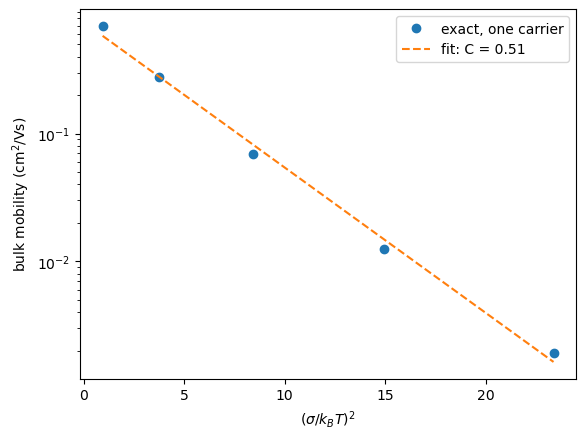

In [17]:
sigmas = np.array([0.025, 0.05, 0.075, 0.1, 0.125])
kT = 0.025852  # eV at 300 K
mu_sigma = []
for s in sigmas:
    run(f'xtp_tools -e latticegen -c job_name=disorder_{s} dims="10 10 10" energy.sigma={s}')
    run(f'xtp_run -e kmcmultiple -c carriertype=hole field="1e6 0 0" runtime=1000 outputtime=0 resultfile=disorder.dat ratefile=x occfile=x -f disorder_{s}.hdf5')
    mu_sigma.append(results("disorder.dat")["exact_mobility"])
x = (sigmas / kT) ** 2
slope, offset = np.polyfit(x, np.log(mu_sigma), 1)
plt.semilogy(x, mu_sigma, "o", label="exact, one carrier")
plt.semilogy(x, np.exp(offset + slope * x), "--", label=f"fit: C = {np.sqrt(-slope):.2f}")
plt.xlabel(r"$(\sigma/k_BT)^2$")
plt.ylabel("bulk mobility (cm$^2$/Vs)")
plt.legend()
plt.show()

## Summary and next steps

* `grw` gives exact ToF times and mobilities for one or two carriers; `kmctof` simulates the same experiment and adds transit-time distributions, transient currents, many carriers and pulses.
* `kmcmultiple` gives bulk mobilities and diffusion tensors at a given carrier density, with the exact single-carrier values as reference.
* ToF mobilities of thin samples exceed the bulk mobility when transport is dispersive.
* `kmclifetime` gives exciton lifetimes, diffusion lengths and where excitons decay, again with exact single-exciton values.

On a real morphology, the state file comes from the mapping and rate workflow (site energies, couplings, reorganization energies) shown in the other tutorials; the transport calculators are used exactly as here. The *Transport Simulations* chapter of the manual lists the options and a checklist.